# NFL Win Prediction: MLP

A neural network (multilayer perceptron) that predicts whether a team wins a game. The inputs are the team's stats averaged over its last 3 games, whether it's at home, and its win rate so far this season. It uses the same train and validation seasons as the Bayesian model so the results can be compared.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import keras
from keras.models import Model
from keras.layers import Input, Dense, Dropout
from keras.optimizers import Adam
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, log_loss

# Folder written by the data processing notebook
DATA_DIR = Path("../Data/data/processed")

In [2]:
# the test seasons (2022-2026) aren't used until the final model is picked
train = pd.read_csv(DATA_DIR / "nfl_train.csv")
validation = pd.read_csv(DATA_DIR / "nfl_validation.csv")

# the input features are listed in feature_descriptions.csv from the data processing notebook
features = pd.read_csv(DATA_DIR / "feature_descriptions.csv")["feature"].tolist()

print("Rows (train / validation):", len(train), len(validation))
print(len(features), "features:", features)

Rows (train / validation): 9518 2064
19 features: ['passing_yards_avg_last_3', 'passing_tds_avg_last_3', 'passing_interceptions_avg_last_3', 'passing_epa_avg_last_3', 'rushing_yards_avg_last_3', 'rushing_tds_avg_last_3', 'rushing_epa_avg_last_3', 'receiving_yards_avg_last_3', 'def_sacks_avg_last_3', 'def_interceptions_avg_last_3', 'def_tds_avg_last_3', 'pt_net_yards_avg_last_3', 'fumbles_lost_total_avg_last_3', 'total_offensive_yards_avg_last_3', 'total_team_tds_avg_last_3', 'turnover_margin_avg_last_3', 'fg_pct_last_3', 'is_home', 'prior_win_rate']


In [3]:
# the features are on really different scales (passing yards is in the hundreds and fg %
# is between 0 and 1), so standardize them. the mean and sd come from the training set only
scaler = StandardScaler()
X_train = scaler.fit_transform(train[features])
X_val = scaler.transform(validation[features])

y_train = train["win"].to_numpy()
y_val = validation["win"].to_numpy()

In [4]:
# 2 hidden layers with relu and a sigmoid output, so the model gives P(win)
keras.utils.set_random_seed(42)  # so results are the same each run

inpx = Input(shape=(len(features),))
hidden1 = Dense(32, activation="relu")(inpx)
drop1 = Dropout(0.2)(hidden1)
hidden2 = Dense(16, activation="relu")(drop1)
drop2 = Dropout(0.2)(hidden2)
output = Dense(1, activation="sigmoid")(drop2)

model = Model(inpx, output)
model.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 19)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,185 (4.63 KB)

 Trainable params: 1,185 (4.63 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(X_train, y_train, epochs=30, batch_size=32,
                    validation_data=(X_val, y_val), verbose=0)

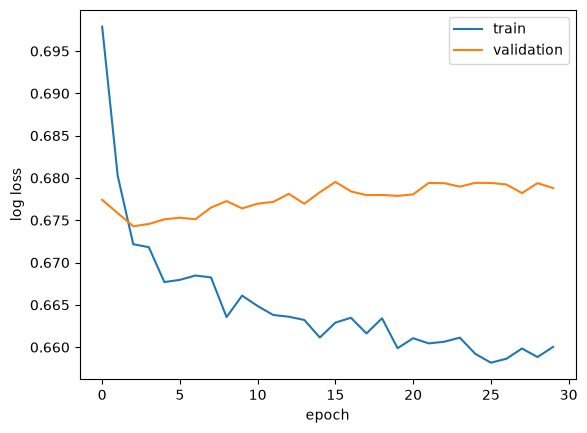

In [6]:
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("log loss")
plt.legend()
plt.show()

In [7]:
p_val = model.predict(X_val, verbose=0).ravel()
print("validation accuracy:", round(accuracy_score(y_val, p_val > 0.5), 3))
print("validation log loss:", round(log_loss(y_val, p_val), 4))

# baseline: always pick the home team
print("always pick the home team:", round(accuracy_score(y_val, validation["is_home"]), 3))

validation accuracy: 0.576
validation log loss: 0.6788
always pick the home team: 0.534


The validation loss is lowest after about 3 epochs and then slowly goes up. The training loss keeps going down the whole time, so the model starts to overfit pretty early.

Validation accuracy is about 58%. That's better than always picking the home team (53%) but worse than the Bayesian model (about 63% on the same seasons). One big reason is that the model only sees the team's own stats. It doesn't know anything about the opponent, so a good team playing a bad team looks the same as a good team playing another good team.